# Lab 07 — Regression with PCA, and a first k-means

*Machine Learning and Data Mining — Claudio Sartori, University of Bologna*

## Goal of this lab

Two topics today. First **regression** (Lecture 16): baselines, linear regression and how to read it, a transformed target,
penalized models, and **PCA as a preparation step** before a regressor (Lecture 15). Then a **first k-means exercise**
(Lecture 19) on a new dataset: scaling, choice of $K$, stability, and giving a meaning to the clusters.

| # | Step | Data | Where |
|---|---|---|---|
| 1 | Baselines, linear regression, RMSE / MAE / $R^2$ with CV | NordicMart, annual spend | A |
| 2 | Residuals, coefficients, a log target | NordicMart, annual spend | A |
| 3 | OLS, ridge, lasso on correlated attributes | diabetes | B |
| 4 | **PCA before regression**: which components, how many | diabetes | B |
| 5 | Many attributes: polynomial features with PCA, ridge or lasso; the test set, once | diabetes | B |
| 6 | k-means: scaling, choice of $K$, stability, meaning of the clusters | wine | C |
| ★ | Ridge as a "soft" PCA; silhouette plot | | B, C |

- **Part A (≈ 25 min)** — NordicMart: how much will a customer spend?
- **Part B (≈ 45 min)** — diabetes: penalties and principal components.
- **Part C (≈ 45 min)** — wine: a first k-means.
- Exercises marked ★ are optional: do them if you have time, or at home.

### How to work (as in Labs 1–6)

- Write code in the empty cells; write **answers in markdown cells**, not in comments.
- Raw data are never modified: every change goes into a copy with a new name.
- Every random step gets a fixed `random_state`, so that your numbers are the same as the slides'.
- Every comparison is made with **cross-validation on the training part**; the test set is opened **once**, at the end of
  Part B, for the model we choose.
- Before closing: **Kernel → Restart & Run All**.

## Setup

New imports: the regressors and the regression measures of Lecture 16 (`DummyRegressor`, `LinearRegression`, `RidgeCV`,
`LassoCV`, `TransformedTargetRegressor`, `PolynomialFeatures`, `root_mean_squared_error`...), `KMeans` and the clustering measures of
Lecture 19, and two datasets distributed with `scikit-learn`: `load_diabetes` and `load_wine`.

`scoring` names: `scikit-learn` always **maximizes** a score, so errors are returned with a minus sign
(`"neg_root_mean_squared_error"`, `"neg_mean_absolute_error"`); the function `evaluate` below turns them back into positive
errors. It returns the CV mean (and the standard deviation over the five folds) of RMSE, MAE and $R^2$ of one model;
`table` does the same for a dictionary of models. Run the cells, do not change them.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, LassoCV
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.cluster import KMeans
from sklearn.metrics import (root_mean_squared_error, mean_absolute_error, r2_score,
                             silhouette_score, silhouette_samples, adjusted_rand_score, confusion_matrix)
from sklearn.datasets import load_diabetes, load_wine
import sklearn

DATA_DIR = Path("../../data")
NORDICMART_FILE = DATA_DIR / "nordicmart_customers.csv"
SEED = 42

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.0.5


In [2]:
cv = KFold(n_splits=5, shuffle=True, random_state=0)       # the target is numeric: KFold, not StratifiedKFold
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

def evaluate(model, X, y, cv=cv):
    s = cross_validate(model, X, y, cv=cv, scoring=SCORING)
    rmse, mae, r2 = -s["test_rmse"], -s["test_mae"], s["test_r2"]
    return pd.Series({"CV RMSE": rmse.mean(), "std RMSE": rmse.std(), "CV MAE": mae.mean(),
                      "CV R2": r2.mean(), "std R2": r2.std()})

def table(models, X, y):
    return pd.DataFrame({name: evaluate(m, X, y) for name, m in models.items()}).T.round(3)

# Part A — NordicMart: how much will a customer spend?

Workshop question 2 (Lecture 5): *predict the annual spend of a customer* (`annual_spend`, in euros) from what we know
about them. Same customers and same split as in Lectures 11–16; the attributes are those of Lecture 16, with the fixed recodes of
Lecture 6. `churned` is **not** an attribute (question A1.3).

In [3]:
df = pd.read_csv(NORDICMART_FILE)

def recode(d):                                     # FIXED steps of the EDA log (Lecture 6)
    return pd.DataFrame({
        "tier": d["tier"],
        "age": d["age"].replace(0, np.nan),
        "recency": d["days_since_last_buy"].replace(999, np.nan),
        "never_bought": (d["days_since_last_buy"] == 999).astype(int),
        "sessions": d["web_sessions_month"].fillna(0),
        "store_only": d["web_sessions_month"].isna().astype(int),
        "tickets": d["tickets_90d"]}, index=d.index)

X = recode(df)
y = df["annual_spend"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=df["churned"], random_state=SEED)

num = ["age", "recency", "never_bought", "sessions", "store_only", "tickets"]
def prep(scale=True):                              # Lecture 16: one-hot tier; median imputation (+ standardization)
    num_steps = [SimpleImputer(strategy="median")] + ([StandardScaler()] if scale else [])
    return make_column_transformer((OneHotEncoder(handle_unknown="ignore"), ["tier"]),
                                   (make_pipeline(*num_steps), num), verbose_feature_names_out=False)

print(f"training: {len(y_train)} customers | test: {len(y_test)} customers")
y_train.describe().round(1).to_frame("annual spend (EUR), training").T

training: 2100 customers | test: 900 customers


,count,mean,std,min,25%,50%,75%,max
"annual spend (EUR), training",2100.0,793.1,684.7,48.5,358.4,576.1,983.4,6181.2


## A1. Baselines first

Every regression model must beat a **constant** prediction (Lecture 16). With `table`, compare on `X_train`, `y_train`:

- `"mean"`: `DummyRegressor()` (always predicts the mean of the training folds);
- `"median"`: `DummyRegressor(strategy="median")`;
- `"linear, tier only"`: `make_pipeline(make_column_transformer((OneHotEncoder(), ["tier"])), LinearRegression())`;
- `"linear, all"`: `make_pipeline(prep(), LinearRegression())`.

Keep the result in `res_A`.

In [4]:
# your code here


,CV RMSE,std RMSE,CV MAE,CV R2,std R2
mean,683.012,47.293,472.807,-0.001,0.001
median,716.014,50.036,438.413,-0.100,0.008
"linear, tier only",568.228,38.601,372.684,0.306,0.036
"linear, all",567.715,39.611,372.987,0.307,0.036


**Questions.**

1. The median baseline has a **lower** MAE but a **higher** RMSE than the mean baseline. Why?
1. How much better than the mean is the linear model, in euros and in $R^2$? And what do the other six attributes add to the tier?
1. Why is `churned` not among the attributes, although it is in the table and correlated with spend?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 
1. 

## A2. Residuals and coefficients

1. With `cross_val_predict(<linear, all>, X_train, y_train, cv=cv)` obtain a CV prediction `pred` for every training customer.
   Draw two plots side by side, coloured by tier: actual vs predicted spend (with the diagonal), and residual vs predicted.
1. Standard deviation of the residuals for each tier.
1. Fit `make_pipeline(prep(scale=False), LinearRegression())` on the training part and print the coefficients with
   `get_feature_names_out()` of the first step: they are in **euros per unit** of each attribute.
   Then fit a linear regression on `sessions` alone and print its coefficient.

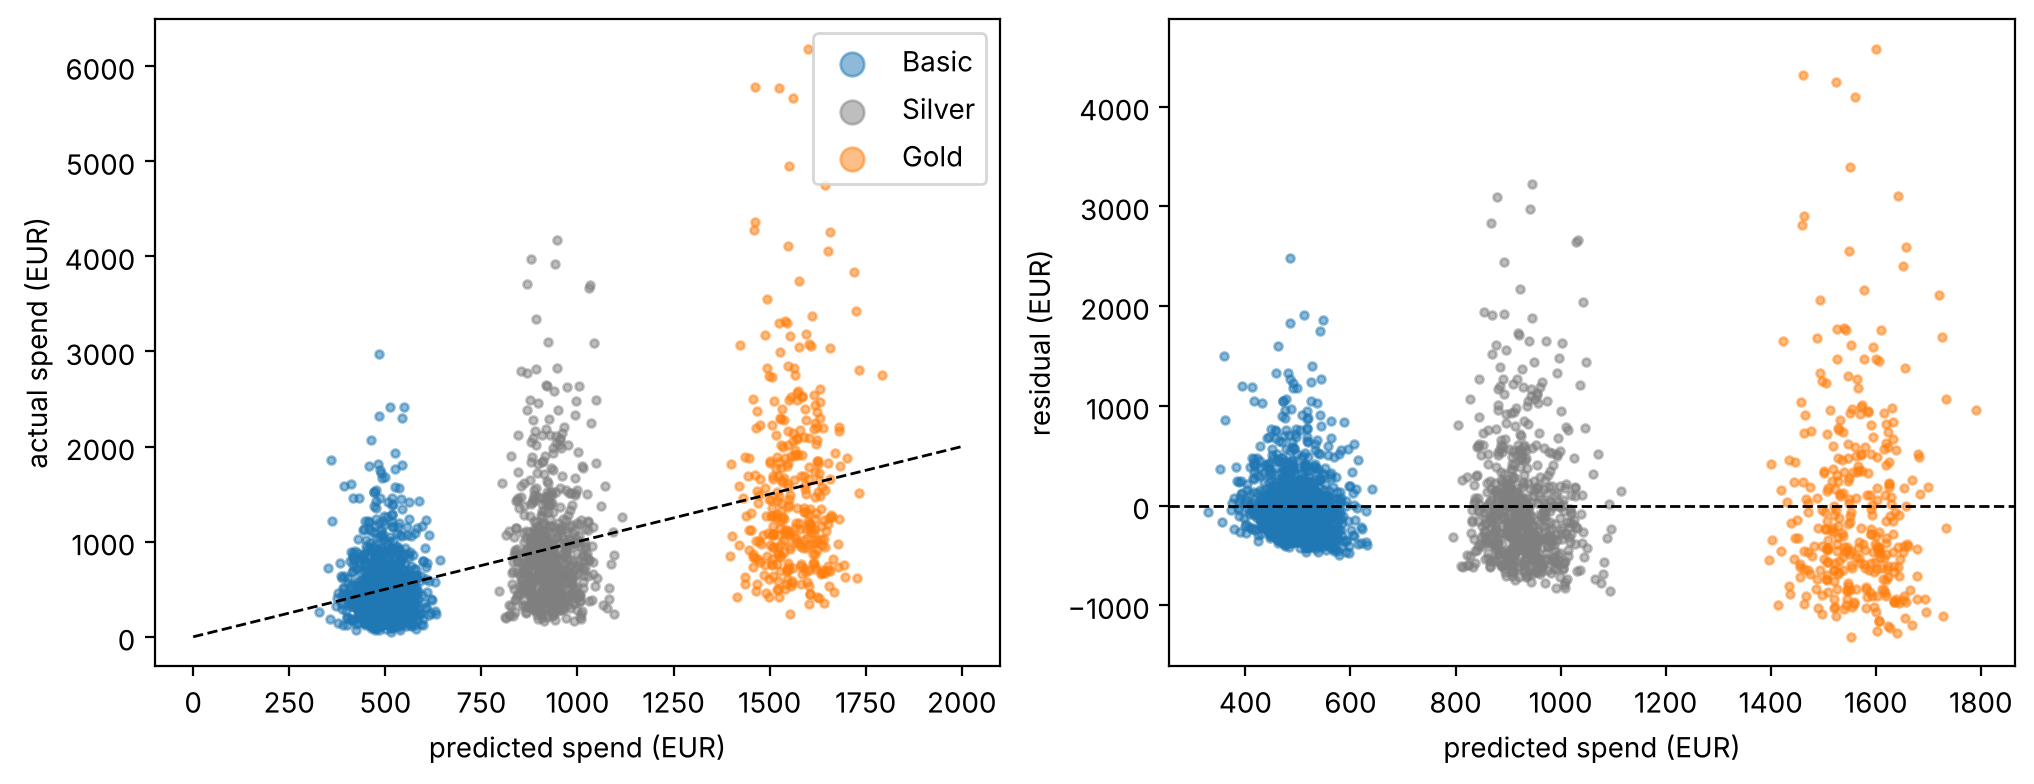

tier,Basic,Gold,Silver
residual std (EUR),338.0,972.0,618.0


,tier_Basic,tier_Gold,tier_Silver,age,recency,never_bought,sessions,store_only,tickets
EUR per unit,-472.4,539.9,-67.5,-3.0,-0.1,22.5,18.2,3.5,13.2


intercept 1076.0
sessions alone: 106.4 EUR per session


In [5]:
# your code here


**Questions.**

1. The predictions form three vertical bands. Why? What does the residual plot say about the assumption of a constant error?
1. Read the coefficient of `sessions` in the full model. Why is it so much smaller than the coefficient of `sessions` alone?
1. The three tier coefficients sum to (about) zero and the intercept is about 1076. Why can we not read the tier coefficients alone?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 
1. 

## A3. A log target

Lecture 16: when errors grow with the level, model $\log y$ and transform the predictions back.

1. With `table`, compare `"linear"` (as above) with
   `"linear, log target"`: `TransformedTargetRegressor(make_pipeline(prep(), LinearRegression()), func=np.log10, inverse_func=lambda z: 10 ** z)`.
1. With `cross_val_predict`, compute for both the **median** absolute error.

In [6]:
# your code here


,CV RMSE,std RMSE,CV MAE,CV R2,std R2
linear,567.715,39.611,372.987,0.307,0.036
"linear, log target",583.981,40.467,356.840,0.267,0.028


median absolute error: linear 255.0 | log target 213.0


**Question.** Which of the two models is better? What would you ask the marketing manager before choosing?

**Answer.** *Write your answer here (double-click to edit).*

# Part B — Diabetes: penalties and principal components

The diabetes data of Lecture 16: 442 patients, 10 attributes (age, sex, body mass index `bmi`, blood pressure `bp`, six blood
serum measurements `s1`–`s6`), target: a measure of disease progression one year later. Same split and CV as in the slides.

In [7]:
D = load_diabetes(as_frame=True, scaled=False)
Xd, yd = D.data, D.target
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.3, random_state=SEED)
ALPHAS_RIDGE, ALPHAS_LASSO = np.logspace(-2, 5, 60), np.logspace(-2, 2, 60)
print(f"training: {len(yd_train)} | test: {len(yd_test)} | target: mean {yd.mean():.1f}, std {yd.std():.1f}")
Xd_train.corr().round(2).loc[["s1", "s2", "s3", "s4"], ["s1", "s2", "s3", "s4", "s5"]]

training: 309 | test: 133 | target: mean 152.1, std 77.1


,s1,s2,s3,s4,s5
s1,1.00,0.89,0.04,0.56,0.53
s2,0.89,1.00,-0.19,0.65,0.31
s3,0.04,-0.19,1.00,-0.73,-0.39
s4,0.56,0.65,-0.73,1.00,0.63


## B1. OLS, ridge and lasso on the ten attributes

1. With `table`, compare on `Xd_train`: `"mean"` (`DummyRegressor()`), `"OLS"` (`StandardScaler` + `LinearRegression`),
   `"ridge CV"` (`StandardScaler` + `RidgeCV(ALPHAS_RIDGE, cv=cv)`), `"lasso CV"` (`StandardScaler` +
   `LassoCV(alphas=ALPHAS_LASSO, cv=cv, max_iter=100000)`). Keep the result in `res_B`.
1. Fit the three linear models on the whole training part and put their **standardized** coefficients side by side in a
   DataFrame (one column per model). Print the $\alpha$ chosen by `RidgeCV` (`alpha_`) and by `LassoCV`.

In [8]:
# your code here


,CV RMSE,std RMSE,CV MAE,CV R2,std R2
mean,78.518,7.766,67.020,-0.030,0.038
OLS,56.605,6.380,46.101,0.457,0.102
ridge CV,56.597,6.342,46.406,0.458,0.099
lasso CV,56.661,6.159,46.281,0.456,0.103


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
OLS,1.4,-12.5,26.2,18.6,-43.3,24.3,5.7,14.0,31.6,2.0
ridge,1.7,-11.2,25.6,17.3,-7.9,-2.2,-9.5,8.3,17.5,3.1
lasso,1.0,-11.1,26.9,17.8,-10.4,-0.0,-8.5,7.6,19.4,2.1


alpha: ridge 20.99 | lasso 0.579


**Questions.**

1. The three linear models have practically the same CV error. Then what is the penalty good for, here?
1. Look at `s1` and `s2` (correlation 0.90). What do OLS, ridge and lasso do with them?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 

## B2. The principal components of the diabetes attributes

1. `pca_d = make_pipeline(StandardScaler(), PCA()).fit(Xd_train)`. Print the explained variance ratio of each component and its cumulative.
1. Compute the scores of the training patients (`pca_d.transform(Xd_train)`) and the **correlation of each component with the
   target** `yd_train` (e.g. with `np.corrcoef`, or putting the scores in a DataFrame and using `corrwith`).
1. Show the loadings of PC1 and PC2 (`pca_d[-1].components_`, one row per component).

In [9]:
# your code here


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
variance ratio,0.396,0.147,0.126,0.098,0.068,0.060,0.054,0.044,0.008,0.001
cumulative,0.396,0.543,0.668,0.767,0.835,0.894,0.948,0.991,0.999,1.000
corr. with y,0.546,-0.200,0.262,-0.307,0.004,-0.127,0.044,-0.011,0.006,-0.069


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
PC1,0.20,0.16,0.31,0.25,0.36,0.36,-0.28,0.44,0.38,0.33
PC2,0.16,-0.37,-0.16,-0.02,0.54,0.41,0.57,-0.14,-0.03,-0.08


**Questions.**

1. How many components for 90% of the variance? Is PC1 easy to name?
1. Are the components sorted by their usefulness for predicting the target? Which ones matter, and what does it mean for PCA before a regressor?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 

## B3. Principal component regression (PCR)

1. For $k = 1, \dots, 10$ compute `evaluate` of `make_pipeline(StandardScaler(), PCA(k), LinearRegression())`; keep the CV RMSE in a
   Series `pcr_curve` (index $k$). Plot it, with the CV RMSE of OLS and of ridge (from `res_B`) as horizontal lines.
1. Choose $k$ with `GridSearchCV` (parameter `pca__n_components`, values 1–10, `scoring="neg_root_mean_squared_error"`, `cv=cv`).
1. Check that PCR with all 10 components gives **the same predictions** as OLS (`np.allclose` on the test attributes is fine: we only
   compare two models, we do not measure an error).

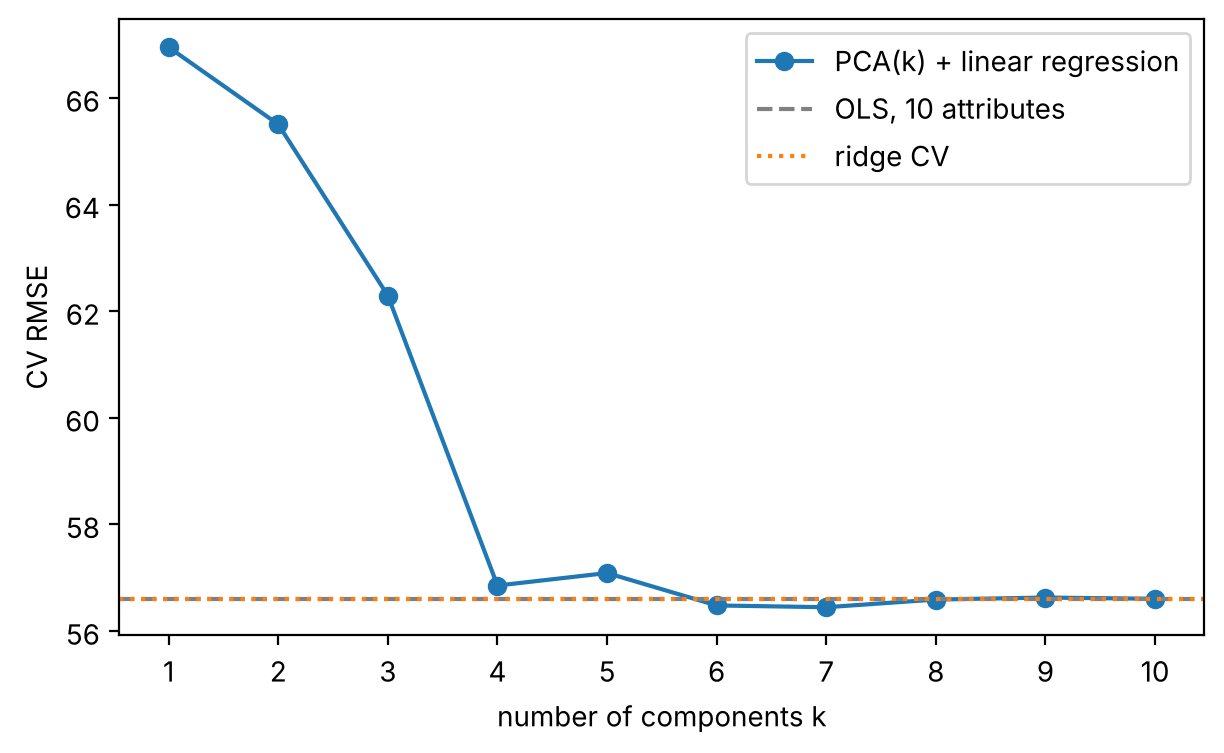

best k: 7 | CV RMSE 56.4
PCR(10) == OLS: True


,1,2,3,4,5,6,7,8,9,10
CV RMSE,67.0,65.5,62.3,56.9,57.1,56.5,56.4,56.6,56.6,56.6


In [10]:
# your code here


**Questions.**

1. Why does the error drop sharply between $k = 3$ and $k = 4$?
1. Why is PCR with 10 components exactly OLS? Then, on these data, what does PCA give us?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 

## B4. Many attributes: polynomial features

With all the products of pairs and the squares of the 10 attributes (degree 2) we get 65 attributes for about 250 patients per training
fold. Preparation (Lecture 16): `P2 = [StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler()]`.

1. With `table`, compare on `Xd_train`:
   - `"OLS, 65 attributes"`: `make_pipeline(*P2, LinearRegression())`;
   - `"PCA + OLS, k by CV"`: a `GridSearchCV` over `make_pipeline(*P2, PCA(), LinearRegression())` with `pca__n_components` in
     [5, 10, 15, 20, 30, 40], scoring `"neg_root_mean_squared_error"`, `cv=cv`;
   - `"ridge CV"`: `make_pipeline(*P2, RidgeCV(np.logspace(-2, 4, 40), cv=cv))`;
   - `"lasso CV"`: `make_pipeline(*P2, LassoCV(alphas=np.logspace(-2, 2, 40), cv=cv, max_iter=100000))`.

   The models with an inner CV (the `*CV` regressors and the grid search) are evaluated by the outer CV of `table`: this is
   **nested** CV (Lecture 10a), an honest estimate of the whole procedure "choose the hyperparameter, then fit".
1. Choose a final model among all those of Part B, fit it on the whole training part and compute RMSE and $R^2$ **on the test set**,
   once. Compare with OLS on the 10 attributes, on the test set as well.

In [11]:
# your code here


,CV RMSE,std RMSE,CV MAE,CV R2,std R2
"OLS, 65 attributes",68.359,5.512,53.747,0.202,0.165
"PCA + OLS, k by CV",61.480,5.704,49.336,0.345,0.182
ridge CV,59.967,6.351,48.728,0.382,0.153
lasso CV,58.344,6.130,47.925,0.419,0.124


k chosen on the whole training part: 20


TEST lasso CV, 65 attributes  RMSE 51.5  R2 0.509
TEST OLS, 10 attributes       RMSE 53.1  R2 0.477
lasso: non-zero coefficients 14 of 65


**Questions.**

1. Rank the four procedures. Why does OLS suffer here, and why does PCA help it but less than the lasso?
1. Which model did you choose, and why? Is its advantage on the test set reliable?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 

## B5. Ridge as a "soft" PCA ★

Lecture 16 says that ridge shrinks the weights along the principal directions, the more the smaller their variance, while PCR keeps
or drops them, all or nothing. With the objective of `Ridge`, $\|\mathbf{y} - Z\mathbf{w}\|^2 + \alpha \|\mathbf{w}\|^2$ on standardized
attributes, the fitted values along principal direction $j$ are multiplied by
$$ f_j = \frac{d_j^2}{d_j^2 + \alpha}, \qquad d_j^2 = (n - 1)\,\lambda_j $$
where $\lambda_j$ is the variance of component $j$ and $n$ the number of records.

1. Compute $f_j$ for the ten components of B2 with the $\alpha$ chosen by `RidgeCV` in B1, and the factors of PCR with $k = 6$ (1 for the
   first six, 0 for the others). Plot both against $j$.

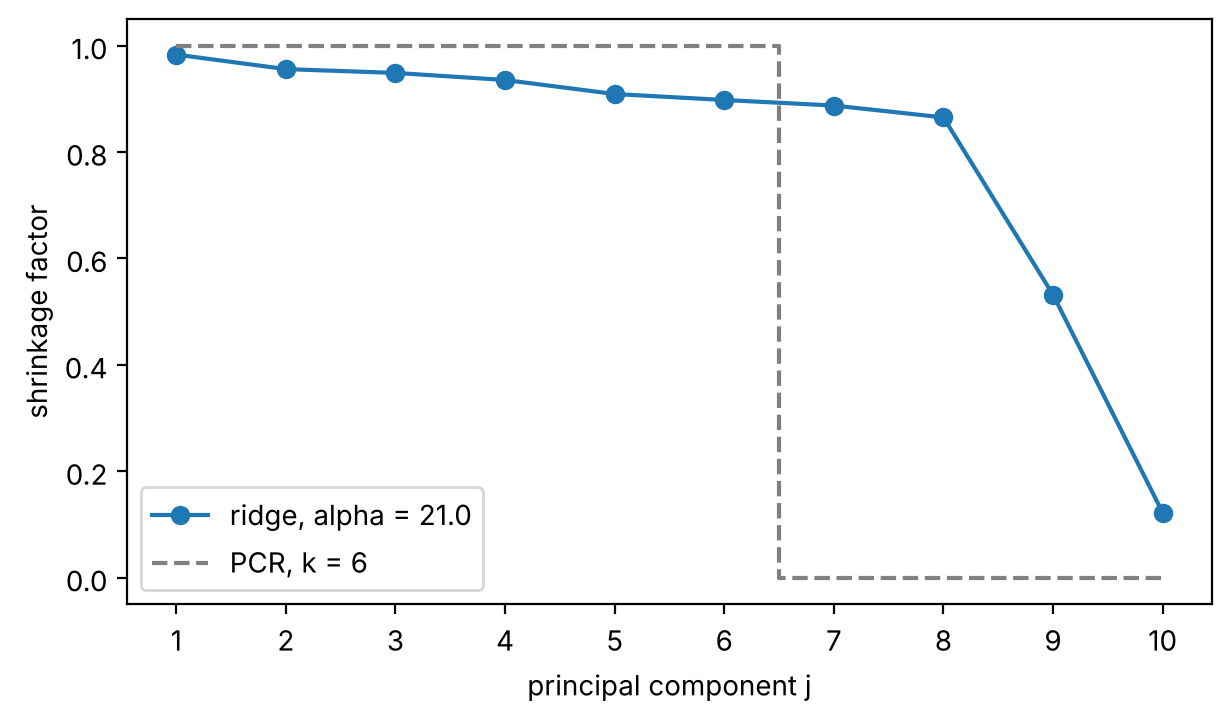

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
ridge factor,0.983,0.956,0.949,0.935,0.909,0.898,0.887,0.865,0.532,0.122


In [12]:
# your code here


**Answer.** *Write your answer here (double-click to edit).*

# Part C — A first k-means: wines

178 Italian wines from the same region, 13 attributes from a chemical analysis (alcohol, acidity, phenols, colour intensity,
proline...), and the **cultivar** of each wine (3 grape varieties). Clustering has **no target**: we use the 13 attributes only, and keep
the cultivar apart, as a variable **not used** — at the end we check whether the clusters find the cultivars (gold standard, Lecture 19).
No split: as for NordicMart in Lecture 19, we describe these 178 wines, we do not predict.

In [13]:
W = load_wine(as_frame=True)
Xw = W.data                                        # 13 attributes, no missing values
cultivar = W.target                                # NOT used in the clustering
Xw.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


## C1. Scaling first

1. Run `KMeans(n_clusters=3, n_init=10, random_state=0)` on the **raw** attributes `Xw`, and on the standardized attributes with
   `make_pipeline(StandardScaler(), KMeans(...))` (same parameters). For both, compute the adjusted Rand index (ARI) with the cultivar.
1. For the raw clustering, print the centroids (`cluster_centers_`) of `proline`, `magnesium` and `alcohol`.

In [14]:
# your code here


ARI with the cultivar: raw 0.371 | standardized 0.897


,proline,magnesium,alcohol
0,458.2,92.3,12.5
1,1195.1,105.5,13.8
2,728.3,103.6,12.9


**Question.** What did k-means do on the raw data, and why?

**Answer.** *Write your answer here (double-click to edit).*

## C2. Choosing $K$

1. For $K = 2, \dots, 8$, on the **standardized** attributes `Zw = StandardScaler().fit_transform(Xw)`, compute the SSE (`inertia_`) and the
   silhouette (`silhouette_score`) of `KMeans(K, n_init=10, random_state=0)`. Plot the two curves (two y axes, as in the slides:
   `ax2 = ax.twinx()`).
1. Compute the silhouettes on the **raw** attributes too, for the same values of $K$.

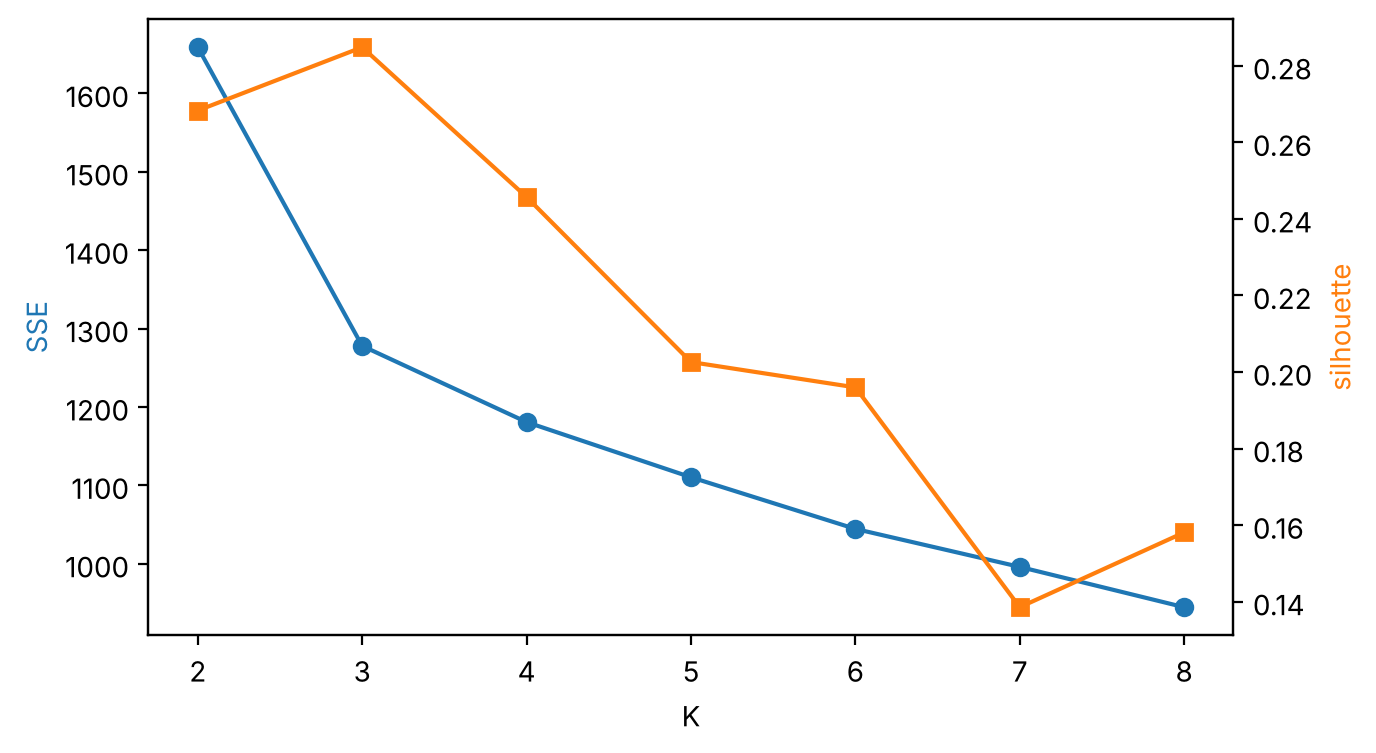

,2,3,4,5,6,7,8
SSE,1659.008,1277.928,1180.738,1110.365,1044.470,995.995,944.559
silhouette,0.268,0.285,0.246,0.203,0.196,0.139,0.158
silhouette raw,0.657,0.571,0.562,0.549,0.566,0.562,0.541


In [15]:
# your code here


**Questions.**

1. Which $K$ do the two curves suggest? Is the elbow as clear as the silhouette?
1. The raw silhouettes (≈ 0.55–0.66) are about twice the standardized ones. Is the raw clustering better?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 

## C3. Stability

With `n_init=1` k-means runs once, from one k-means++ start. On `Zw` with $K = 3$, run `KMeans(3, n_init=1, random_state=s)` for
`s` in 0–19 and compute the ARI of each run with the reference partition `lab_std` (from C1). Then do the same with $K = 5$
(reference: `KMeans(5, n_init=10, random_state=0)`).

In [16]:
# your code here


K=3: ARI with the reference, min 0.882  median 0.982  runs with ARI=1: 7/20
K=5: ARI with the reference, min 0.457  median 0.647  runs with ARI=1: 0/20


**Answer.** *Write your answer here (double-click to edit).*

## C4. Giving a meaning to the clusters

Use the standardized clustering with $K = 3$ of C1 (`lab_std`). The toolbox of Lecture 19:

1. **Profiles**: size of each cluster and medians of the attributes in the original units (`Xw.groupby(lab_std).median()`); a heat map
   of the **standardized** centroids (`plt.imshow`, attributes on one axis, clusters on the other, a diverging colour map such as
   `"RdBu_r"` centred on 0).
1. **A picture**: scatter of the first two principal components of `Zw`, coloured by cluster.
1. **A variable not used**: `pd.crosstab(lab_std, cultivar)`.
1. **A surrogate tree**: a `DecisionTreeClassifier(max_depth=2, random_state=0)` that predicts `lab_std` from the raw attributes;
   its fidelity (5-fold CV accuracy with `cross_val_score`) and its rules (`export_text`).

,size,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,65,12.25,1.61,2.24,20.0,88.0,2.20,2.03,0.35,1.56,2.9,1.04,2.84,495.0
1,51,13.11,3.27,2.38,21.0,97.0,1.65,0.70,0.47,1.10,7.3,0.67,1.68,620.0
2,62,13.74,1.76,2.45,17.0,105.5,2.82,2.98,0.29,1.90,5.4,1.07,3.17,1072.5


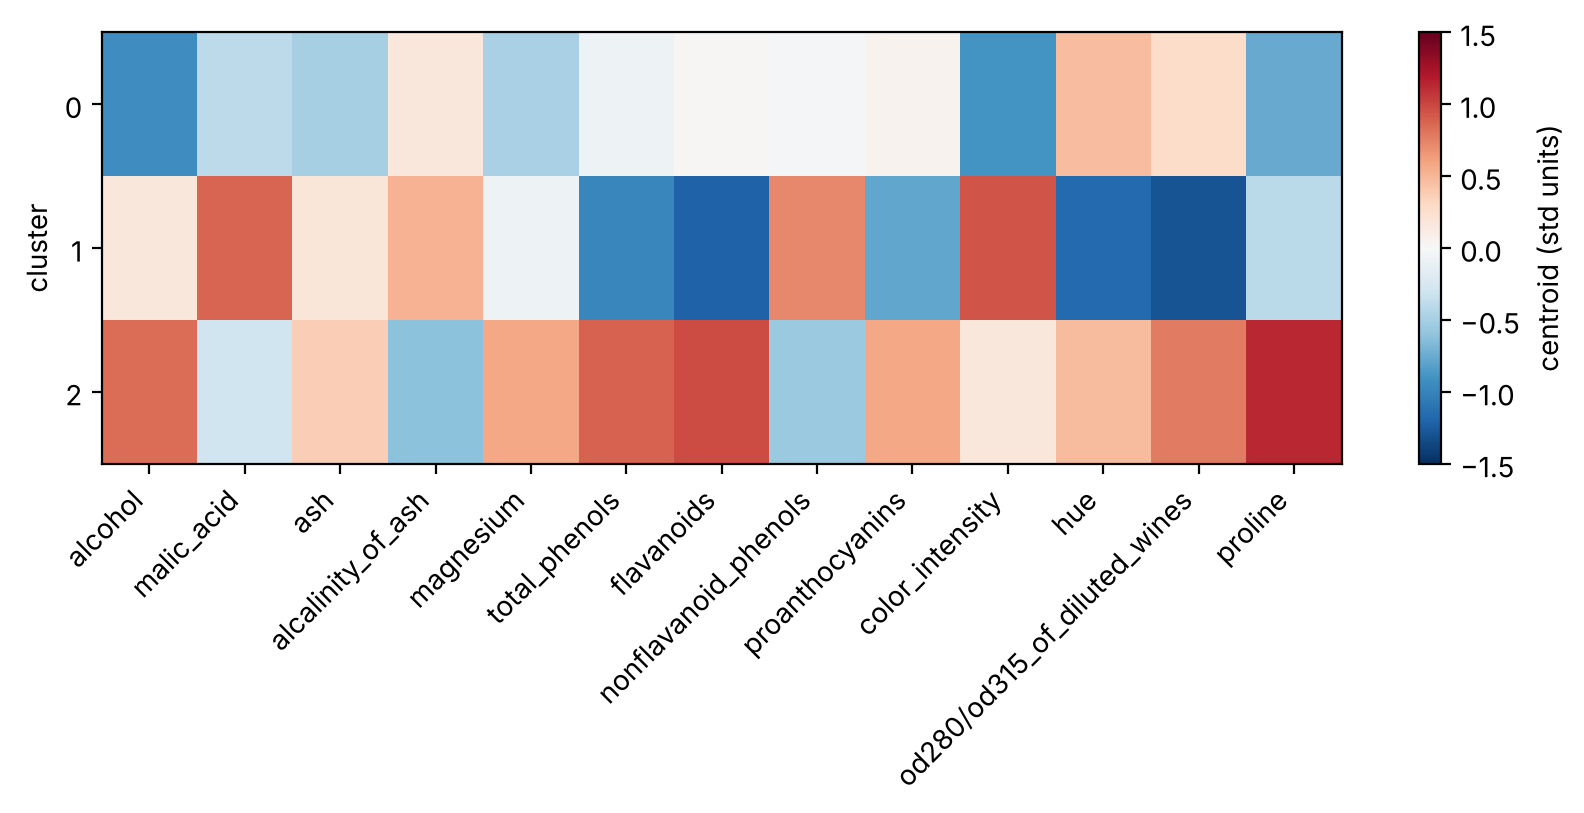

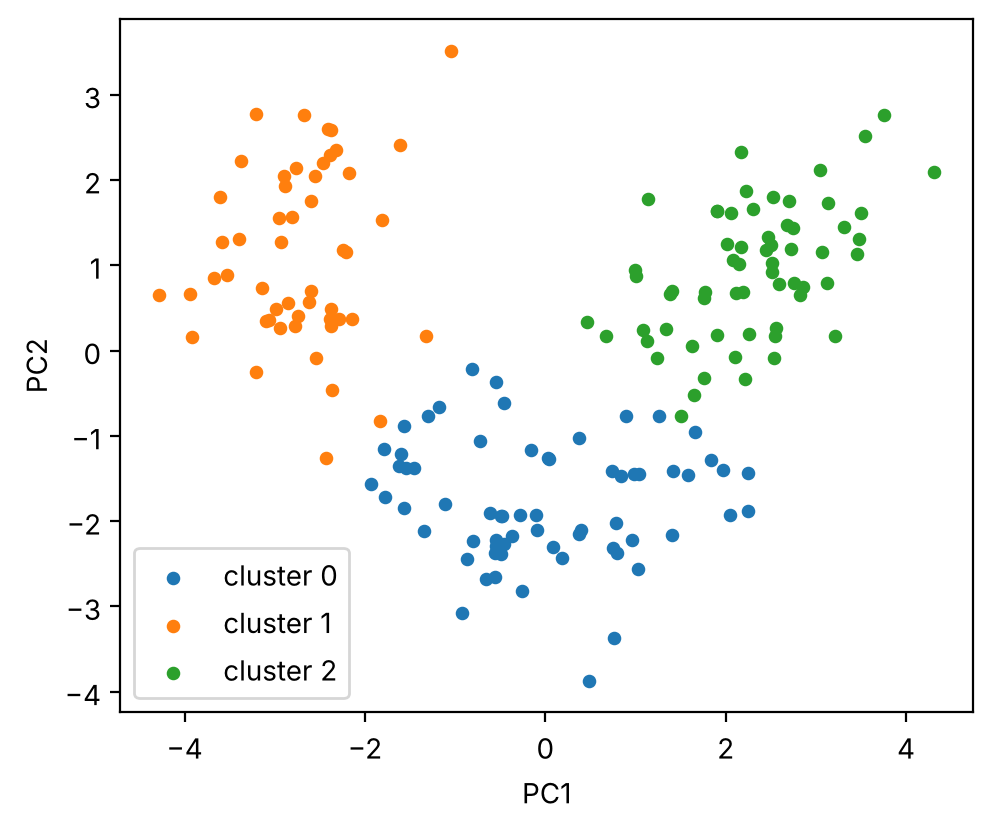

cultivar,0,1,2
cluster,,,
0,0,65,0
1,0,3,48
2,59,3,0


fidelity (CV accuracy): 0.888
|--- proline <= 755.00
|   |--- od280/od315_of_diluted_wines <= 2.19
|   |   |--- class: 1
|   |--- od280/od315_of_diluted_wines >  2.19
|   |   |--- class: 0
|--- proline >  755.00
|   |--- flavanoids <= 2.17
|   |   |--- class: 1
|   |--- flavanoids >  2.17
|   |   |--- class: 2



In [17]:
# your code here


**Questions.**

1. Describe each cluster in one line, from the profiles and the heat map.
1. How well do the clusters match the cultivars? Why is this an independent check?
1. What do the rules of the surrogate tree say, and how much can we trust them?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 
1. 

## C5. Silhouette of each wine ★

1. With `silhouette_samples(Zw, lab_std)` draw the silhouette plot of Lecture 19: for each cluster, its objects sorted by silhouette
   as horizontal bars, stacked; a vertical line at the mean silhouette.
1. How many wines have a negative silhouette? To which cultivar do they belong?

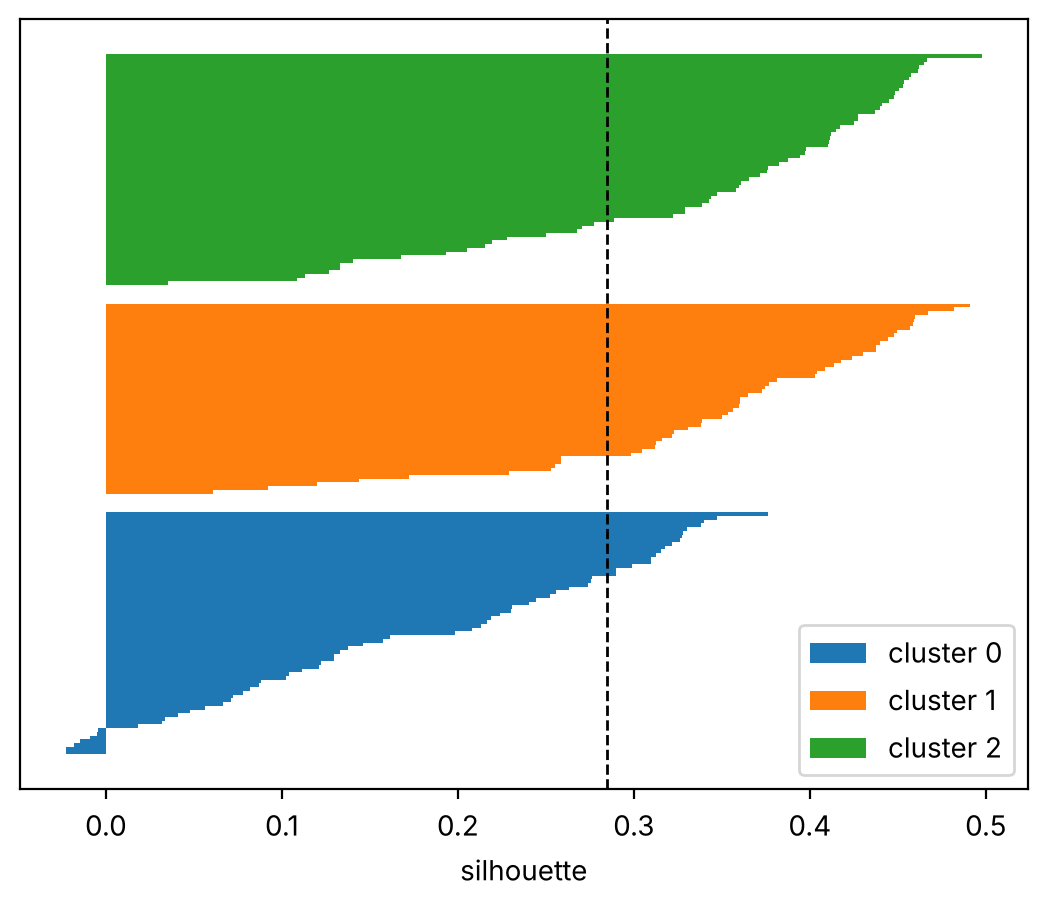

negative silhouettes: 7 | cultivars: {1: 7}


In [18]:
# your code here


**Answer.** *Write your answer here (double-click to edit).*

## Results log

Complete the log (double-click to edit): one row per comparison of Parts A and B, with the CV RMSE and your verdict.

| Part | Data | Model | CV RMSE | CV $R^2$ | Verdict |
|---|---|---|---|---|---|
| *A1* | *NordicMart* | *mean baseline* | *683* | *0.00* | *the bar to beat* |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |

## Before you close

1. **Kernel → Restart & Run All**: the notebook must run from top to bottom without errors.
1. Check that the test sets were used **once**, at the end of B4.

In [19]:
# quick self-check
assert len(X_test) == 900 and len(Xd_test) == 133
assert round(res_A.loc["mean", "CV RMSE"]) == 683 and round(res_A.loc["linear, all", "CV RMSE"]) == 568
assert round(res_B.loc["OLS", "CV RMSE"], 1) == 56.6
assert round(adjusted_rand_score(cultivar, lab_std), 3) == 0.897
assert choice["silhouette"].idxmax() == 3
print("ok")

ok
